# Does excitement differ between rainy and drier days?

**Question:** Do students select “It is the most exciting” more often on rainy days?

We combine the professor's survey with daily Copenhagen rainfall, calculate percentages, and draw one bar chart. This notebook contains the original weather download plus the analysis; the separate `motivation_year.ipynb` contains supervised learning.

Run cells from top to bottom with the working directory set to this notebook’s `assignment/` folder.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo
from IPython.display import display, Markdown

### Download or read the weather data
Source: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), using **ECMWF ERA5** estimates for Copenhagen. `rain_sum` is daily rainfall in millimetres, using Copenhagen's local calendar day.

[Open the exact API request](https://archive-api.open-meteo.com/v1/archive?latitude=55.6761&longitude=12.5683&start_date=2020-08-26&end_date=2026-09-21&daily=rain_sum&timezone=Europe%2FCopenhagen&models=era5).

Historical daily rainfall data for Copenhagen, downloaded from Open-Meteo.

In [6]:
import requests
from pathlib import Path

# Reuse the downloaded data. Delete the CSV only if you want a fresh download.
if Path("../dataset/copenhagen_weather_daily.csv").exists():
    weather_df = pd.read_csv("../dataset/copenhagen_weather_daily.csv")
    print("Loaded saved weather data.")
else:
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    
    # Download the full date range. Later, we will match only the survey dates.
    parameters = {
        "latitude": 55.6761,            # Copenhagen
        "longitude": 12.5683,
        "start_date": "2020-08-26",
        "end_date": "2026-09-21",
        "daily": "rain_sum",            # Total rainfall each day, in mm
        "timezone": "Europe/Copenhagen",
        "models": "era5",               # Historical weather estimates
    }
    
    response = requests.get(url, params=parameters, timeout=30)
    response.raise_for_status()         # Report an error if the request failed.
    data = response.json()              # Convert the response to a Python dictionary.
    
    weather_df = pd.DataFrame(data["daily"])
    weather_df.columns = ["date", "rain_mm"]
    
    weather_df.to_csv("../dataset/copenhagen_weather_daily.csv", index=False)
    weather_df.head()

Loaded saved weather data.


### Read and combine the student data

The shared function in `load_student_data.py` reads all four formats, removes password columns, and combines the tables. Each call returns a fresh table.

In [7]:
from load_student_data import load_student_data

# Read and combine the four survey files using the shared Python function.
students_df = load_student_data()
print("Total responses:", len(students_df))

Total responses: 223


### Clean the dates
The file named 2023 contains answers from **2020, 2021, and 2023**. We use the timestamp year, not the filename.

The sources use different time zones. Convert to Copenhagen time before extracting the date. For older timestamps without a zone, we assume Copenhagen time. This is the longest cleaning step because each file uses a different format.

In [8]:
copenhagen = ZoneInfo("Europe/Copenhagen")

def to_copenhagen(timestamp, source):
    if source == 2023:
        date = datetime.strptime(timestamp, "%d/%m/%Y %H:%M:%S")
        date = date.replace(tzinfo=copenhagen)
    elif source == 2024:
        date = datetime.strptime(timestamp.replace(" GMT+3", ""), "%Y/%m/%d %I:%M:%S %p")
        date = date.replace(tzinfo=timezone(timedelta(hours=3)))
    elif source == 2025:
        date = datetime.fromisoformat(timestamp)
    else:
        date = datetime.strptime(timestamp.replace(" PDT", ""), "%Y/%m/%d %I:%M:%S %p")
        date = date.replace(tzinfo=timezone(timedelta(hours=-7)))
    return date.astimezone(copenhagen)

students_df["local_time"] = [to_copenhagen(t, s) for t, s in
                             zip(students_df["timestamp"], students_df["source_file"])]
students_df["date"] = students_df["local_time"].dt.strftime("%Y-%m-%d")
students_df["year"] = students_df["local_time"].dt.year
print(students_df["year"].value_counts().sort_index())

year
2020    50
2021     7
2023    33
2024    38
2025    50
2026    45
Name: count, dtype: int64


### Clean the reasons
Remove missing or blank answers rather than treating them as “not excited.” Convert text to lowercase and remove surrounding spaces.

Students could select several options. We check whether the exact option **“It is the most exciting”** appears anywhere in the answer. Other choices can appear alongside it. This measures selection of an option, not a person's mood.

In [9]:
valid = students_df["course_reason"].notna() & students_df["course_reason"].astype(str).str.strip().ne("")
print("Excluded missing or blank answers:", (~valid).sum())
students_df = students_df.loc[valid].copy()
students_df["reason_clean"] = students_df["course_reason"].str.lower().str.strip()
students_df["exciting"] = [int("it is the most exciting" in answer)
                           for answer in students_df["reason_clean"]]

Excluded missing or blank answers: 0


### Match rainfall to each answer
Match by date. Several students can share one weather day, so the weather table must have unique dates. Check that every survey date has rainfall; missing weather must not be treated as a dry day.

For this comparison, **rainy means at least 1 mm**. The other group is labelled **below 1 mm**, because it can include a little rain. This is a chosen threshold.

In [10]:
assert not weather_df["date"].duplicated().any()
data = students_df.merge(weather_df, on="date", how="left", validate="many_to_one")
assert data["rain_mm"].notna().all(), "Some survey dates have no weather data."
data["rain_group"] = np.where(data["rain_mm"] >= 1, "At least 1 mm", "Below 1 mm")
print("Matched responses:", len(data))
print("Distinct weather days:", data["date"].nunique())

Matched responses: 223
Distinct weather days: 45


### Compare percentages
Each student counts once, even if they selected several reasons. We show both the number of students and the number of dates so the sample size is clear.

,students,days,selected_exciting,exciting_percent
rain_group,,,,
Below 1 mm,100,26,48,48.0
At least 1 mm,123,19,65,52.8


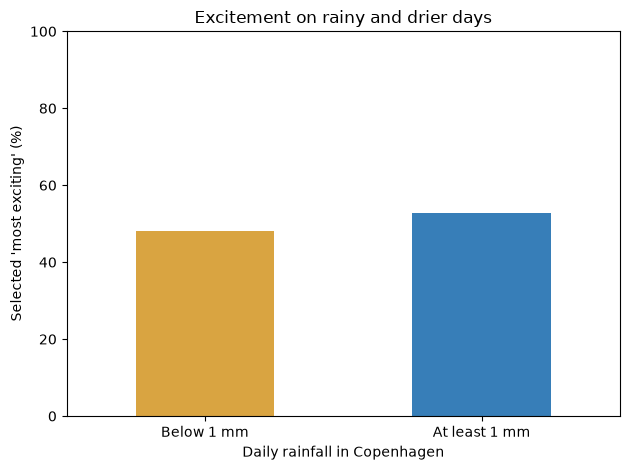

In [11]:
comparison = data.groupby("rain_group").agg(
    students=("exciting", "size"),
    days=("date", "nunique"),
    selected_exciting=("exciting", "sum"),
)
comparison["exciting_percent"] = 100 * comparison["selected_exciting"] / comparison["students"]
comparison = comparison.reindex(["Below 1 mm", "At least 1 mm"])
display(comparison.round(1))

comparison["exciting_percent"].plot.bar(color=["#d9a441", "#377eb8"], rot=0)
plt.ylabel("Selected 'most exciting' (%)")
plt.xlabel("Daily rainfall in Copenhagen")
plt.title("Excitement on rainy and drier days")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Check the years before interpreting the result
An apparent weather difference may instead be a difference between cohorts. The table below shows percentages within each year; blank cells mean that group has no responses.

In [12]:
by_year = data.pivot_table(index="year", columns="rain_group", values="exciting", aggfunc="mean") * 100
display(by_year.round(1))
print("Largest numbers of responses on a single day:")
display(data["date"].value_counts().head(3))

rain_group,At least 1 mm,Below 1 mm
year,,
2020,43.8,50.0
2021,NaN,71.4
2023,NaN,36.4
2024,50.0,47.2
2025,61.5,63.6
2026,55.9,54.5


Largest numbers of responses on a single day:


date
2020-08-26    47
2023-09-07    32
2025-09-02    23
Name: count, dtype: int64

### Answer

In [14]:
wet = comparison.loc["At least 1 mm", "exciting_percent"]
dry = comparison.loc["Below 1 mm", "exciting_percent"]
direction = "more" if wet > dry else "less" if wet < dry else "equally"
display(Markdown(f"""In this sample, students selected **'most exciting' {direction} often on rainy days**:
**{wet:.1f}%** on days with at least 1 mm, compared with **{dry:.1f}%** on days below 1 mm.
The difference is **{wet - dry:+.1f} percentage points**.

This is a descriptive association, not evidence that rain changes students' motivation."""))

In this sample, students selected **'most exciting' more often on rainy days**:
**52.8%** on days with at least 1 mm, compared with **48.0%** on days below 1 mm.
The difference is **+4.8 percentage points**.

This is a descriptive association, not evidence that rain changes students' motivation.

### Limitations
- Students from the same day share the same weather. The 223 responses cover only 45 dates; 47 answers come from one day in 2020.
- Years and programmes may explain the difference. We have not performed a significance test or established causation.
- We assume respondents were in Copenhagen. A daily total can include rain after the answer was submitted.
- Choosing “most exciting” is not a direct measurement of mood. The result also depends on our 1 mm threshold.

**Conclusion:** this notebook answers what happened in this sample. It does not establish a general weather effect.